---
title: "A Bayesian go/no-go for a drug candidate, in PyTorch"
description: "A go/no-go clinical decision built as Bayesian logistic regression in PyTorch. With 250 trials the Bayesian and frequentist estimates agree; the credible interval is the payoff, and the prior earns its keep when trials are few."
date: "2026-08-10"
tags: ["Bayesian statistics", "Drug discovery", "PyTorch", "Uncertainty quantification", "Clinical development"]
readingTime: "11 min"
repo: "https://github.com/tensoromics/notes/tree/main/bayesian-clinical-risk-pytorch"
draft: false
---

Developing new medicines requires pharmaceutical companies to make significant investment decisions based on incomplete biological data. You will never have certainty. The goal is to estimate the risk from the data you have today, and be honest about how uncertain it is.

Bayesian methods are built for exactly this. This note works through a full example in PyTorch: a go/no-go call on one drug candidate.

## Evaluating the Clinical Risk

Let us say a biotech/pharma company is making a go/no-go decision on whether to advance a new drug candidate, **Compound 42**, into further development.

A review of the drug's profile shows:
1.  **Efficacy:** Strong tumor shrinkage in animal models.
2.  **Mechanism of Action:** Completely novel, targeting a protein never before tested in humans.
3.  **Liver Toxicity:** Mildly elevated liver enzymes, which is a known clinical risk factor.

Standard machine learning models return a single probability with no sense of how far to trust it, and when precedents are few they can lock onto a handful of outcomes and report a falsely confident answer. We need an approach that measures its own uncertainty, and that stays calibrated when the data is thin.

## Formulating the Statistical Problem

Let us frame the clinical challenge as a computational problem that we can solve.


At its core, determining the viability of an asset is a binary classification problem: the preclinical profile either supports a "go" decision (1) or a "no-go" decision (0). While the underlying biology exists on a continuous spectrum of risk and efficacy, the business reality demands a discrete choice. We must compress all that biological nuance into a single, definitive action: commit the capital to advance the drug, or halt development to avoid sunk costs.

A standard frequentist logistic regression runs a weighted sum of the features through the logistic (sigmoid) function to turn them into a success probability:

$$ p(\text{success} \mid \mathbf{x}) = \sigma\!\big(w_1\,\text{Efficacy} + w_2\,\text{Mechanism} + w_3\,\text{Toxicity} + b\big), \qquad \sigma(z) = \frac{1}{1 + e^{-z}} $$

Each historical outcome is treated as a Bernoulli draw from that probability, and the fit calculates a single, fixed optimal value for each weight $w_j$.

However, fixed weights cannot express uncertainty. To properly quantify the risk of a multi-million dollar go/no-go decision, we frame this as a **Bayesian inference** problem. Instead of finding a single weight, we treat each weight as a random variable with its own probability distribution, governed by Bayes' Theorem:

$$ \text{Posterior} \propto \text{Likelihood} \times \text{Prior} $$

Here is how that translates to our clinical challenge:
*   **The Prior:** Our baseline pharmacological assumptions before looking at the data. For example, we already *know* that liver toxicity is generally harmful, so we assign it a negative prior distribution.
*   **The Likelihood:** What the historical data tells us. Does the historical evidence confirm our assumptions, or does it challenge them?
*   **The Posterior:** Our updated belief. This is a final probability distribution that combines our Prior and the Likelihood. A wide posterior distribution means the model is highly uncertain; a narrow posterior means the model is confident.

## Bayesian computing with PyTorch

Calculating the exact posterior is intractable for models like this. To solve it, we use [Variational Inference](https://arxiv.org/abs/1601.00670). We will task PyTorch with finding an *approximation* of the Posterior by turning it into an optimization problem. We will train the model to minimize a custom loss function called the **Evidence Lower Bound (ELBO)**, which elegantly balances fitting the historical data (Likelihood) without straying too far from our biological reality (Prior).

To solve this Bayesian inference problem, we are building our probabilistic model natively in **[PyTorch](https://pytorch.org)**.

We chose PyTorch because it allows us to build custom Bayesian layers from scratch using the *[Reparameterization Trick](https://arxiv.org/abs/1312.6114)*. This gives us granular control over the network graph and lets us integrate the risk engine with larger deep learning architectures (a text model over clinical notes, or a graph neural network over chemical structures) with GPU training intact.

For a three-feature model on a few hundred trials, PyTorch is a big hammer. We use it to make the mechanics explicit and because the same layer scales to far larger models, but plenty of lighter tools fit a problem this size. If you would rather not hand-write the ELBO, [Pyro](https://pyro.ai)/[NumPyro](https://num.pyro.ai) and [TensorFlow Probability](https://www.tensorflow.org/probability) offer higher-level abstractions. For exact MCMC on a dataset this size, [PyMC](https://www.pymc.io) and [Stan](https://mc-stan.org) (via [CmdStanPy](https://mc-stan.org/cmdstanpy/)) map the posterior with samplers like [NUTS](https://arxiv.org/abs/1111.4246) instead of approximating it, and their R interfaces [brms](https://paulbuerkner.com/brms/) and [rstanarm](https://mc-stan.org/rstanarm/) are biostatistics standards. R also has [R-INLA](https://www.r-inla.org/) for fast approximate inference, plus [JAGS](https://mcmc-jags.sourceforge.io/) and [greta](https://github.com/greta-dev/greta).

## Defining and Simulating Our Data

To ground our Bayesian model, we need two distinct sets of data:
1. **Historical Training Data ($N=250$ trials):** Past clinical programs, used to train the model's weight distributions. (For this tutorial we simulate them; see below.)
2. **The Target Asset Profile:** The specific preclinical metrics of Compound 42 that we want to evaluate for our go/no-go decision.

---

### What the Historical Training Data Contains

Think of this dataset as an internal archive of previous drug development programs. It is structured as a matrix where each row represents a distinct historical drug candidate, and the columns represent its standardized preclinical profile alongside its final clinical outcome:

* **Feature 1 (Efficacy):** A continuous score representing tumor shrinkage or target knockdown, standardized against the industry baseline (mean = 0, standard deviation = 1).
* **Feature 2 (Mechanism of Action):** A binary flag (`0.0` or `1.0`) indicating whether the target was a well-established biological pathway (`0`) or a first-in-class novel target (`1`).
* **Feature 3 (Liver Toxicity):** A continuous score tracking preclinical ALT/AST enzyme elevation relative to safe thresholds.
* **The Target Label ($y$):** A binary outcome (`1` for historical clinical success/approval, `0` for clinical failure/halted development).

This setup assumes a new candidate is *exchangeable* with the archive: the same relationship between the features (efficacy, mechanism, toxicity) and clinical success holds for it too. In practice that means drawing the archive from a comparable population: similar indication, modality, and endpoints. The learned weights cannot speak to a candidate far outside it.

---

### How the Data Was Simulated

Because we do not have a live commercial database hooked up for this tutorial, we simulate $N=250$ synthetic historical trials. To make this simulation clinically realistic, we don't generate success and failure at random. Instead, we define a hidden "ground-truth" logical rule that mirrors real-world pharmacology:

$$ \text{True Logits} = 1.5 \times (\text{Efficacy}) + 0.2 \times (\text{Novel Mechanism}) - 2.8 \times (\text{Liver Toxicity}) $$

* **Efficacy has a strong positive weight ($+1.5$):** Better tumor shrinkage reliably improves the chances of trial success.
* **Novel Mechanism has a slight positive weight ($+0.2$):** First-in-class targets carry potential, but historical uncertainty keeps the boost modest.
* **Liver Toxicity has a severe negative weight ($-2.8$):** Preclinical toxicity heavily penalizes the asset, often overriding positive efficacy metrics.

We pass these logits through a sigmoid function to convert them into probabilities, and compare them against random uniform noise (`torch.rand`) to assign a final binary success (`1`) or failure (`0`) outcome. This introduces realistic clinical noise, acknowledging that even good drugs can occasionally fail due to unforeseen factors.

The generative rule above is not the model. Its coefficients (1.5, 0.2, -2.8) are the hidden truth we invented to manufacture the data; in a real problem you never know them. The model we wrote down earlier, $p = \sigma(\mathbf{w}^\top \mathbf{x} + b)$, never sees them. It only sees the simulated outcomes and has to infer its own weights $w_j$. Whether it recovers something close to the truth (and how sure it is) is the whole test.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# --- Simulate 250 historical clinical trials -----------------------------
torch.manual_seed(42)

X_history = torch.randn(250, 3)
X_history[:, 1] = (X_history[:, 1] > 0).float()          # binarize the Novel Mechanism flag

# Hidden ground-truth rule (the model never sees these coefficients)
true_logits = 1.5 * X_history[:, 0] + 0.2 * X_history[:, 1] - 2.8 * X_history[:, 2]
# Logit -> probability -> Bernoulli outcome: success when sigmoid(logit) > u ~ Uniform(0,1)
y_history = (torch.sigmoid(true_logits) > torch.rand(250)).float().view(-1, 1)

# --- The target candidate profile (Compound 42) ----------------------------
compound_42 = torch.tensor([[1.8, 1.0, 1.2]])              # [efficacy, mechanism, toxicity]

print(f"Historical Features (X_history) Shape: {tuple(X_history.shape)}")
print(f"Historical Labels (y_history) Shape:   {tuple(y_history.shape)}")
print(f"Simulated Historical Success Rate:     {y_history.mean().item()*100:.1f}%")
print(f"Target Asset Profile (Compound 42):      {compound_42.squeeze().tolist()}")

Historical Features (X_history) Shape: (250, 3)
Historical Labels (y_history) Shape:   (250, 1)
Simulated Historical Success Rate:     52.4%
Target Asset Profile (Compound 42):      [1.7999999523162842, 1.0, 1.2000000476837158]


## Visualizing the Data and Positioning Compound 42

Before passing our data into the Bayesian network, let us visualize the data we have with respect to the prior. We want to inspect:
1. **The Historical Baseline:** How past clinical trials are distributed across our three features (Efficacy, Mechanism, and Toxicity).
2. **The Target Asset Fit:** Exactly where **Compound 42** sits relative to that historical distribution.

The plots show the tension in the candidate: strong efficacy pulling toward a go, and elevated toxicity pulling the other way.

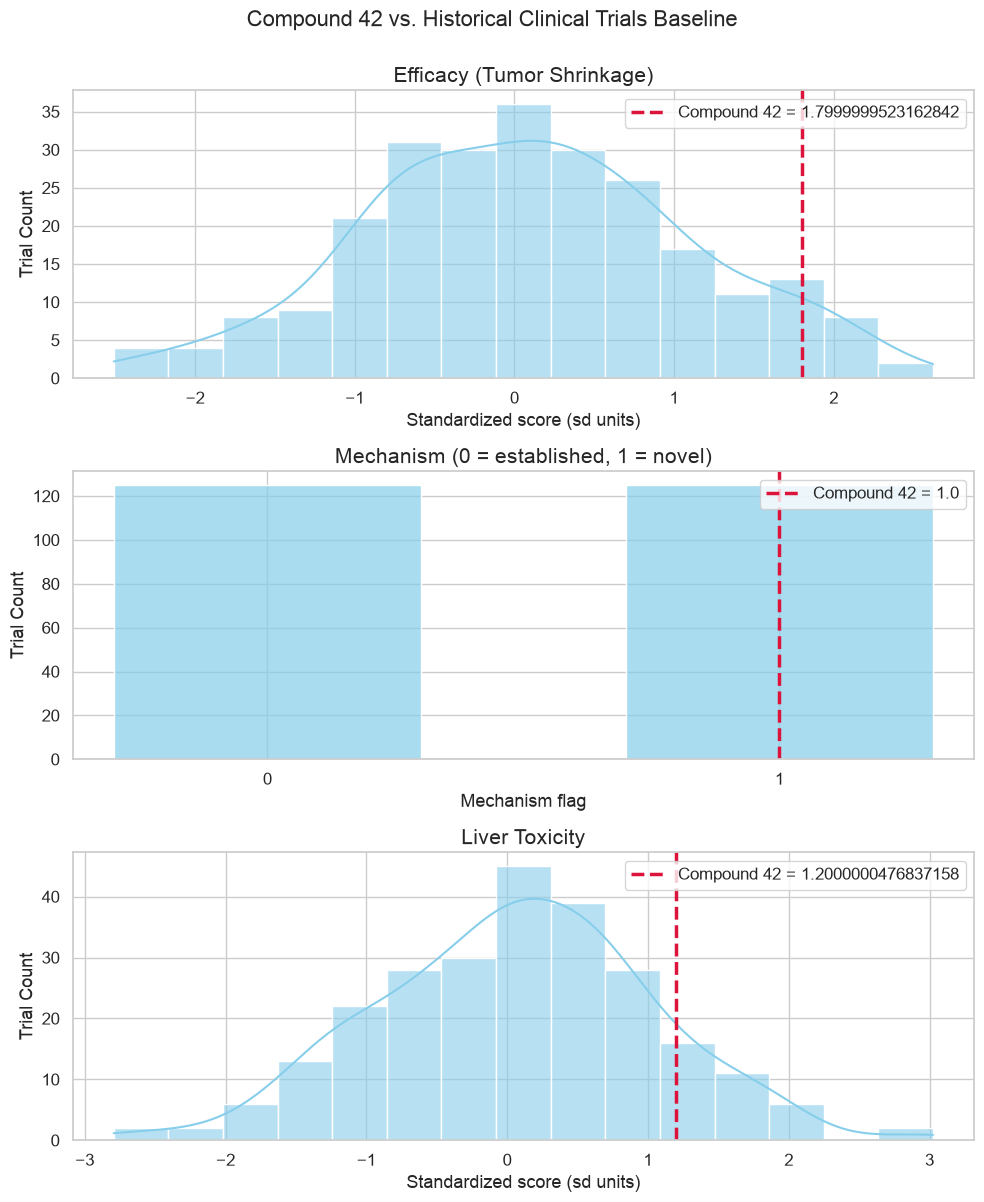

In [2]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
feature_names = ["Efficacy (Tumor Shrinkage)", "Mechanism (0 = established, 1 = novel)", "Liver Toxicity"]
asset_values = compound_42.squeeze().tolist()

for i in range(3):
    if i == 1:                                            # binary feature: counts, not a KDE
        sns.histplot(X_history[:, i].numpy(), ax=axes[i], color="skyblue",
                     alpha=0.7, discrete=True, shrink=0.6)
        axes[i].set_xticks([0, 1]); axes[i].set_xlabel("Mechanism flag", fontsize=13)
    else:
        sns.histplot(X_history[:, i].numpy(), ax=axes[i], kde=True,
                     color="skyblue", alpha=0.6, bins=15)
        axes[i].set_xlabel("Standardized score (sd units)", fontsize=13)
    axes[i].axvline(asset_values[i], color="crimson", linestyle="--", linewidth=2.5,
                    label=f"Compound 42 = {asset_values[i]}")
    axes[i].set_title(feature_names[i], fontsize=15)
    axes[i].set_ylabel("Trial Count", fontsize=13)
    axes[i].tick_params(labelsize=12)
    axes[i].legend(loc="upper right", frameon=True, fontsize=12)

plt.suptitle("Compound 42 vs. Historical Clinical Trials Baseline", fontsize=16, y=1.00)
plt.tight_layout(); plt.show()

## Interpreting Where Compound 42 Falls

The distribution plots show why this is such a hard call:

1. **Efficacy (+1.8 standard deviations):**
   Compound 42 sits far out on the right tail of the historical distribution. It performs better than roughly 94% of historical trials in tumor shrinkage. On efficacy alone, it looks like a strong candidate.
2. **Mechanism of Action (1.0 - First-in-Class):**
   Compound 42 is on the novel side of this binary flag. In our synthetic archive about half the trials are first-in-class as well, so the model has plenty of examples and estimates the mechanism effect directly, and it turns out to be small. Our openness about genuinely unproven mechanisms lives in the wide prior we place on this weight (see the priors below), not in the data.
3. **Liver Toxicity (+1.2 standard deviations):**
   Compound 42's toxicity score is higher than about 88% of the simulated trials, and that is the real danger in this profile. In past clinical data, assets with this level of liver enzyme elevation rarely crossed the finish line successfully.

The efficacy spike (`+1.8`) pulls toward a go; the high toxicity (`+1.2`) pulls the other way. Our Bayesian risk engine has to weigh the two against each other, and report how sure it is.

## Translating Domain Expertise into Biological Priors

Before writing the neural network, we must encode our pharmacological domain expertise into **Priors**.

### Conceptual Check: Feature Space vs. Parameter Space
When moving to Bayesian modeling, it is vital not to confuse two distinct worlds:
1. **Feature Space (The Data):** The actual measurements of our drug candidate or historical trials, such as the histograms we plotted earlier showing where Compound 42's efficacy ($+1.8$) or toxicity ($+1.2$) sits relative to past data. This tells us *what the drug looks like*.
2. **Parameter / Weight Space (The Priors):** The model's internal rules of thumb. Rather than looking at a single drug's data, the prior defines our pre-existing belief about *how the world works* (e.g., historical medical evidence dictates that liver toxicity weights should heavily penalize success).

We do not change a prior because of a single drug's data; instead, our priors act as the stable anchor points that judge the data.

### Defining Our Biological Priors
We encode our pharmacological domain expertise into these weight priors ($\mu$ and $\sigma$):
1. **Efficacy Prior ($\mu = 1.0, \sigma = 0.5$):** Historical data shows higher efficacy generally helps, so we set a positive weight mean with tight confidence.
2. **Novel Mechanism Prior ($\mu = 0.0, \sigma = 2.0$):** First-in-class targets are unproven territory, so we set a neutral mean with a wide uncertainty bound to let the data speak.
3. **Liver Toxicity Prior ($\mu = -2.0, \sigma = 0.5$):** Historical clinical trials heavily penalize toxicity, so we hardcode a strong negative weight mean with tight confidence.

In [3]:
# Biological Priors: [Efficacy, Novel Mechanism, Liver Toxicity]
prior_mus    = torch.tensor([[1.0, 0.0, -2.0]])
prior_sigmas = torch.tensor([[0.5, 2.0,  0.5]])

print("Biological Priors Defined:")
print(f"Prior Means (mu):     {prior_mus.squeeze().tolist()}")
print(f"Prior Sigmas (sigma): {prior_sigmas.squeeze().tolist()}")

Biological Priors Defined:
Prior Means (mu):     [1.0, 0.0, -2.0]
Prior Sigmas (sigma): [0.5, 2.0, 0.5]


## Building the Bayesian Engine in PyTorch

Now we are all set to build the core model.

Standard neural networks use fixed, static weights. Even as a single layer, this works like any Bayesian model: instead of one fixed value per weight, it learns a **distribution** for each weight: a mean $\mu$ and a spread $\sigma$ (stored as an unconstrained $\rho$ that softplus maps to a positive $\sigma$).

To train this network via standard backpropagation, we rely on the **Reparameterization Trick**. Instead of sampling weights directly (which breaks gradient flow), we sample random noise $\epsilon \sim \mathcal{N}(0, 1)$ and scale it by our learned standard deviation:
$$ \text{Weight} = \mu + \sigma \times \epsilon $$

During the forward pass, we also calculate the **KL Divergence** between our learned weight distribution (the Posterior) and our hardcoded biological rules (the Prior). This acts as the mathematical rubber band that prevents the model from ignoring medical reality when it encounters noisy historical data. Sampling the weights this way and adding a KL-to-prior term is the recipe from [*Weight Uncertainty in Neural Networks*](https://arxiv.org/abs/1505.05424); for a broader tour of Bayesian neural networks, see [Jospin et al. (2022)](https://arxiv.org/abs/2007.06823).

In [4]:
from torch.distributions import Normal, kl_divergence

class BayesianIntelligenceLayer(nn.Module):
    def __init__(self, in_features, prior_mus, prior_sigmas):
        super().__init__()
        # Variational parameters of the weight posterior (what we optimize)
        self.weight_mu  = nn.Parameter(torch.Tensor(1, in_features).uniform_(-0.1, 0.1))
        self.weight_rho = nn.Parameter(torch.Tensor(1, in_features).uniform_(-4, -3))
        self.bias = nn.Parameter(torch.zeros(1))                 # point-estimated bias
        # Hardcoded biological reality (the priors, as fixed buffers)
        self.register_buffer("prior_mu",    prior_mus)
        self.register_buffer("prior_sigma", prior_sigmas)

    def forward(self, x):
        weight_sigma = F.softplus(self.weight_rho)               # rho -> positive sigma
        weight = self.weight_mu + weight_sigma * torch.randn_like(self.weight_mu)
        posterior = Normal(self.weight_mu, weight_sigma)
        prior     = Normal(self.prior_mu, self.prior_sigma)
        self.kl_loss = kl_divergence(posterior, prior).sum()
        return F.linear(x, weight, self.bias)

class ClinicalRiskModel(nn.Module):
    def __init__(self, prior_mus, prior_sigmas):
        super().__init__()
        self.bayesian_layer = BayesianIntelligenceLayer(3, prior_mus, prior_sigmas)
    def forward(self, x):
        return torch.sigmoid(self.bayesian_layer(x))

print("Bayesian Intelligence Architecture Initialized Successfully.")

Bayesian Intelligence Architecture Initialized Successfully.


## Training the Model (Optimizing the ELBO)

Now that our single-layer Bayesian Neural Network and our biological priors are set up, we need to train the model on our simulated historical dataset ($N=250$ trials).

In a standard neural network, we minimize a standard loss function like Binary Cross-Entropy (BCE). But in a Bayesian Neural Network, our loss function must balance two competing forces:
1. **The Data Fit (Likelihood):** How well do our sampled weights predict the historical success/failure outcomes ($y\_history$)? Measured using BCE.
2. **The Medical Reality (KL Divergence):** How far have our learned weight distributions strayed from our expert biological priors?

Combining these gives us the **Evidence Lower Bound (ELBO)** loss function:
$$ \text{ELBO Loss} = \text{Binary Cross-Entropy} + \tfrac{1}{N}\,\text{KL Divergence} $$
*(Note: the $1/N$ factor makes this a genuine per-sample ELBO when the BCE is averaged over the $N=250$ trials, and we minimize the negative ELBO. Down-weighting the KL further would erode the prior's influence, so we keep it at full strength.)*

Let's write the training loop using the Adam optimizer.

In [5]:
torch.manual_seed(42)                        # reproducible init + training
model = ClinicalRiskModel(prior_mus, prior_sigmas)
optimizer = torch.optim.Adam(model.parameters(), lr=0.05)

N = X_history.shape[0]
model.train()
for epoch in range(2000):
    optimizer.zero_grad()
    preds = model(X_history)                              # forward pass samples weights (reparameterization trick)
    bce_loss = F.binary_cross_entropy(preds, y_history)  # data-fit term (the likelihood)
    kl_loss  = model.bayesian_layer.kl_loss / N          # prior-penalty term, per-sample ELBO scaling (beta = 1)
    total_loss = bce_loss + kl_loss                       # negative ELBO, the quantity we minimize
    total_loss.backward()
    optimizer.step()
    if (epoch + 1) % 400 == 0:
        print(f"Epoch [{epoch+1}/2000] | BCE: {bce_loss.item():.4f} | KL/N: {kl_loss.item():.4f} | Total: {total_loss.item():.4f}")

post_mu = model.bayesian_layer.weight_mu.detach().squeeze().tolist()
print("\nTraining Complete!")
print("Posterior weight means [Efficacy, Mechanism, Toxicity]:", [round(w, 2) for w in post_mu])

Epoch [400/2000] | BCE: 0.3355 | KL/N: 0.0163 | Total: 0.3519
Epoch [800/2000] | BCE: 0.3299 | KL/N: 0.0159 | Total: 0.3458
Epoch [1200/2000] | BCE: 0.3346 | KL/N: 0.0147 | Total: 0.3494
Epoch [1600/2000] | BCE: 0.3334 | KL/N: 0.0157 | Total: 0.3491
Epoch [2000/2000] | BCE: 0.3362 | KL/N: 0.0165 | Total: 0.3527

Training Complete!
Posterior weight means [Efficacy, Mechanism, Toxicity]: [1.37, 0.5, -2.76]


The model was shown the data, never the generative rule. Line the three sets of numbers up:

| Weight | Generative truth | Prior mean (sigma) | Learned posterior |
|---|---|---|---|
| Efficacy   | +1.5 | +1.0 (0.5) | +1.37 |
| Mechanism  | +0.2 |  0.0 (2.0) | +0.50 |
| Toxicity   | -2.8 | -2.0 (0.5) | -2.76 |

Efficacy and toxicity land within a whisker of the hidden truth. The data pulled toxicity from its prior of -2.0 out to -2.76, right next to the true -2.8, while the mechanism weight stays small and noisy. The model recovered the truth without being shown it.

## Evaluating Compound 42 with Monte Carlo Sampling

In a standard neural network, passing a drug profile through the model once gives you a single number, with no sense of how much to trust it.

Because our model is a **Bayesian Neural Network**, every time we run a forward pass, it samples a slightly different set of weights from our learned weight distributions (Posterior). To get a rigorous clinical risk assessment for **Compound 42**, we use **Monte Carlo Sampling**: we run Compound 42 through the trained model 2,000 times.

This gives us an entire *distribution* of predictions, allowing us to answer:
1. **What is the average predicted success probability?**
2. **How much uncertainty or variance is there around that prediction?**

In [6]:
model.eval()
torch.manual_seed(43)                        # reproducible Monte Carlo
with torch.no_grad():
    # Each pass re-samples the weights, so 2,000 passes trace out the posterior over P(success)
    mc_preds = torch.stack([model(compound_42).squeeze() for _ in range(2000)])

mean_prob = mc_preds.mean().item()
ci_lower, ci_upper = torch.quantile(mc_preds, torch.tensor([0.025, 0.975])).tolist()  # 95% credible interval
THRESHOLD = 0.50                             # advance if mean P(success) >= 50%

print("--- CLINICAL DECISION REPORT: COMPOUND 42 ---")
print(f"Mean Success Probability: {mean_prob*100:.1f}%")
print(f"95% Credible Interval:    [{ci_lower*100:.1f}% - {ci_upper*100:.1f}%]")
print(f"Go/No-Go Threshold:       {THRESHOLD*100:.0f}%")
print(f"P(above threshold):       {(mc_preds >= THRESHOLD).float().mean().item()*100:.0f}%")
print(f"\nRecommendation: {'GO' if mean_prob >= THRESHOLD else 'NO-GO'}")

--- CLINICAL DECISION REPORT: COMPOUND 42 ---
Mean Success Probability: 41.6%
95% Credible Interval:    [22.4% - 63.8%]
Go/No-Go Threshold:       50%
P(above threshold):       23%

Recommendation: NO-GO


### The same call without the Bayesian machinery

Here is the plain logistic regression the Bayesian model has to beat, fit on the same 250 trials with no prior:

In [7]:
def fit_logistic_mle(X, y, iters=300):
    """Plain unregularized logistic regression, fit by Newton-Raphson (IRLS)."""
    Xi = torch.cat([X.double(), torch.ones(len(X), 1, dtype=torch.float64)], dim=1)  # add intercept column
    yv = y.squeeze().double()
    w = torch.zeros(Xi.shape[1], dtype=torch.float64)
    for _ in range(iters):
        p = torch.sigmoid(Xi @ w)                      # current predicted probabilities
        W = (p * (1 - p)).clamp_min(1e-9)              # IRLS weights
        H = Xi.T @ (W.unsqueeze(1) * Xi) + 1e-9 * torch.eye(Xi.shape[1], dtype=torch.float64)  # Hessian
        step = torch.linalg.solve(H, Xi.T @ (p - yv)) # Newton step
        w = w - step
        if torch.norm(step) < 1e-10:
            break
    separated = bool(torch.norm(w[:-1]) > 15)          # weights running off toward infinity => separation
    x7 = torch.tensor([1.8, 1.0, 1.2, 1.0], dtype=torch.float64)  # Compound 42 profile + intercept
    return w, separated, torch.sigmoid(x7 @ w).item()

w_freq, _, p_freq = fit_logistic_mle(X_history, y_history)
print(f"Plain logistic regression, P(success) for Compound 42: {p_freq*100:.1f}%  "
      f"-> {'GO' if p_freq >= 0.5 else 'NO-GO'}")
print(f"Learned weights [eff, mech, tox]: {[round(v, 2) for v in w_freq[:-1].tolist()]}")

Plain logistic regression, P(success) for Compound 42: 38.5%  -> NO-GO
Learned weights [eff, mech, tox]: [1.58, 0.54, -3.17]


## Visualizing the Final Decision Distribution
The plain fit above lands at essentially the same center, about 38%, so with 250 trials the value of the Bayesian model is not a different point estimate but the credible interval around it. We can plot the full Monte Carlo predictive distribution to show both the mean and that interval.

The 2,000 independent forward passes through our Bayesian Neural Network yield a **probability density distribution** rather than a single point estimate. The shape tells us three things:

### 1. The Central Tendency (Mean: 41.6%)
The distribution sits below the **50% Go/No-Go threshold**. With 250 trials behind us, the data itself has already learned a strong toxicity penalty (the posterior toxicity weight settles near $-2.8$), and that pulls the expected success probability down despite the high efficacy.

### 2. The Credible Interval (95% CI: 22.4% to 63.8%)
The interval is wide. Even with a few hundred historical trials, a single-layer model over three noisy features leaves real uncertainty, and the Bayesian posterior reports it honestly instead of collapsing to a falsely precise number. Mean-field variational inference tends to understate posterior variance, so if anything treat this interval as a floor on the true uncertainty.

### 3. It Straddles the Line
Part of the distribution sits above the 50% threshold. The mean leans no-go, but an interval that crosses the line tells executive leadership this is a genuine judgment call, not a settled one. That is exactly the information a bare point estimate would have hidden.

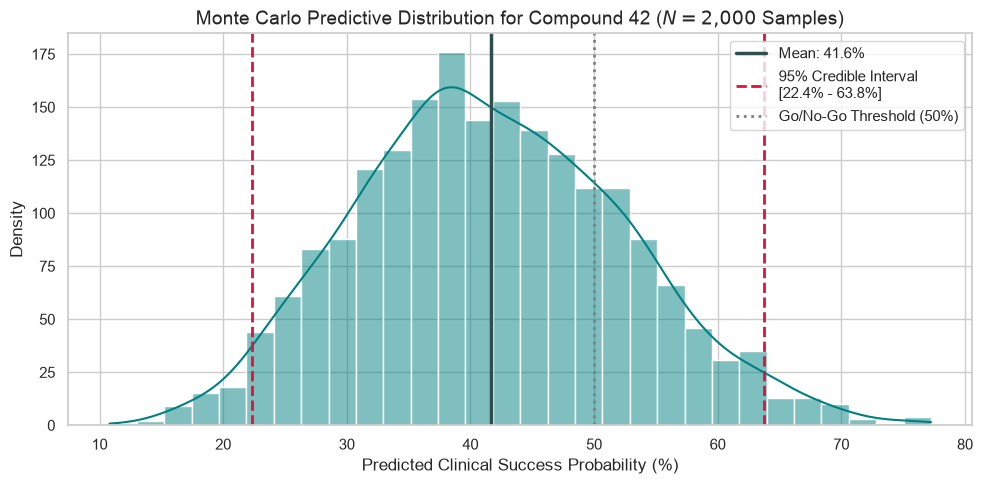

In [8]:
plt.figure(figsize=(10, 5))
sns.histplot(mc_preds.numpy() * 100, kde=True, color="teal", bins=30, alpha=0.5)
plt.axvline(mean_prob*100, color="darkslategray", linewidth=2.5, label=f"Mean: {mean_prob*100:.1f}%")
plt.axvline(ci_lower*100, color="crimson", linestyle="--", linewidth=2,
            label=f"95% Credible Interval\n[{ci_lower*100:.1f}% - {ci_upper*100:.1f}%]")
plt.axvline(ci_upper*100, color="crimson", linestyle="--", linewidth=2)
plt.axvline(THRESHOLD*100, color="gray", linestyle=":", linewidth=2, label="Go/No-Go Threshold (50%)")
plt.title("Monte Carlo Predictive Distribution for Compound 42 ($N=2{,}000$ Samples)", fontsize=14)
plt.xlabel("Predicted Clinical Success Probability (%)", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.legend(loc="upper right", frameon=True)
plt.tight_layout(); plt.show()

## When the Prior Earns Its Keep in a Rare-Disease Trial

With 250 trials, the data alone was rich enough to identify the toxicity penalty; the prior mostly rode along. The regime where the prior does the heavy lifting is the one clinical teams actually fear: **few precedents**, like a rare disease, a novel modality, or a first program in a new indication.

To see it, we shrink the historical archive to just 15 trials and run two models on the same data: a standard (frequentist) logistic regression with no prior, and our Bayesian model with the biological priors we defined earlier.

In [9]:
# A rare-disease-sized evidence base: 15 historical trials (fit_logistic_mle defined earlier)
torch.manual_seed(4)
Xr = torch.randn(15, 3); Xr[:, 1] = (Xr[:, 1] > 0).float()
logits_r = 1.5 * Xr[:, 0] + 0.2 * Xr[:, 1] - 2.8 * Xr[:, 2]
yr = (torch.sigmoid(logits_r) > torch.rand(15)).float().view(-1, 1)

# (1) plain logistic regression, no prior
wr, sep_r, p_mle_r = fit_logistic_mle(Xr, yr)

# (2) Bayesian, same architecture and prior
torch.manual_seed(4)
model_r = ClinicalRiskModel(prior_mus, prior_sigmas)
opt_r = torch.optim.Adam(model_r.parameters(), lr=0.05)
for _ in range(2000):
    opt_r.zero_grad()
    loss = F.binary_cross_entropy(model_r(Xr), yr) + model_r.bayesian_layer.kl_loss / len(Xr)
    loss.backward(); opt_r.step()
model_r.eval()
torch.manual_seed(5)
with torch.no_grad():
    mcr = torch.stack([model_r(compound_42).squeeze() for _ in range(2000)])
mean_r = mcr.mean().item()
lo_r, hi_r = torch.quantile(mcr, torch.tensor([0.025, 0.975])).tolist()

print(f"15 trials, historical success rate: {yr.mean().item()*100:.0f}%\n")
print("Plain logistic regression (no prior)")
print(f"  weights [eff, mech, tox]: {[round(v,1) for v in wr[:-1].tolist()]}")
print(f"  separated (degenerate fit)? {sep_r}")
print(f"  P(success) for Compound 42:       {p_mle_r*100:.1f}%   -> {'GO' if p_mle_r>=0.5 else 'NO-GO'}\n")
print("Bayesian (same prior)")
print(f"  posterior toxicity weight: {model_r.bayesian_layer.weight_mu.detach().squeeze()[2].item():.2f}")
print(f"  mean P(success) for Compound 42:   {mean_r*100:.1f}%")
print(f"  95% credible interval:     [{lo_r*100:.1f}% - {hi_r*100:.1f}%]   -> {'GO' if mean_r>=0.5 else 'NO-GO'}")

15 trials, historical success rate: 47%

Plain logistic regression (no prior)
  weights [eff, mech, tox]: [38.3, -13.5, -39.3]
  separated (degenerate fit)? True
  P(success) for Compound 42:       100.0%   -> GO

Bayesian (same prior)
  posterior toxicity weight: -2.20
  mean P(success) for Compound 42:   38.7%
  95% credible interval:     [6.7% - 83.0%]   -> NO-GO


With only 15 trials, the standard logistic regression [**separates**](https://academic.oup.com/biomet/article-abstract/71/1/1/349338): the data can be split cleanly, so its weights run off toward infinity and it reports a confident **100% chance of success** (a go) on the strength of 15 data points. That is the overconfident false positive the high toxicity should have prevented.

Given the same 15 trials and the same priors, the Bayesian model cannot blow up. The prior keeps the toxicity weight near $-2$ instead of letting it explode; a [weakly informative prior](https://projecteuclid.org/journals/annals-of-applied-statistics/volume-2/issue-4/A-weakly-informative-default-prior-distribution-for-logistic-and-other/10.1214/08-AOAS191.full) is the standard fix for exactly this. It returns a mean near **39%** with a wide 95% interval (roughly **7% to 83%**), a no-go lean honest enough to say *we don't know yet; get more data*.

N= 15 | plain-LR separates  61.0% of draws | LR sd(P) 0.435 | Bayesian 95% width 0.888


N= 30 | plain-LR separates  14.5% of draws | LR sd(P) 0.335 | Bayesian 95% width 0.818


N= 60 | plain-LR separates   1.0% of draws | LR sd(P) 0.218 | Bayesian 95% width 0.691


N=125 | plain-LR separates   0.0% of draws | LR sd(P) 0.159 | Bayesian 95% width 0.416


N=250 | plain-LR separates   0.0% of draws | LR sd(P) 0.126 | Bayesian 95% width 0.348


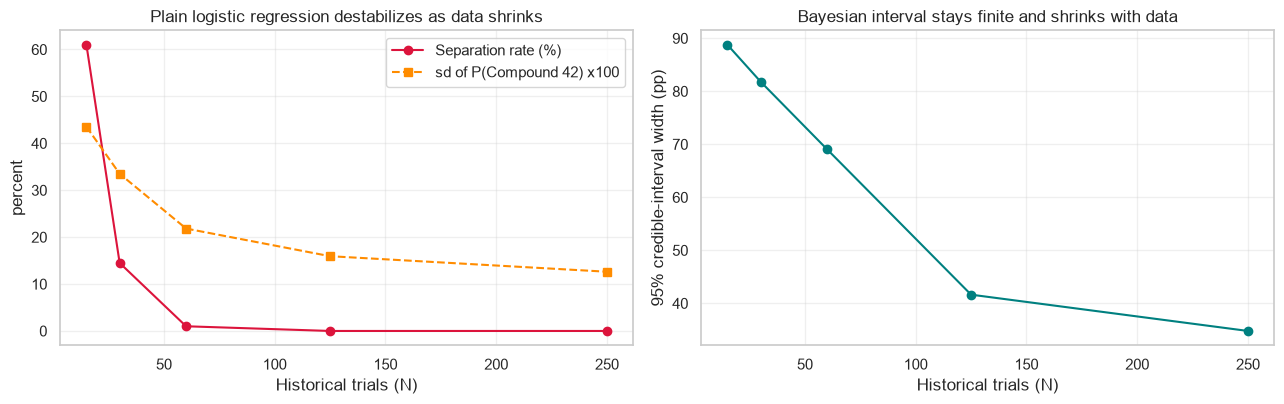

In [10]:
def bayes_ci_width(X, y, seed):
    torch.manual_seed(seed)
    m = ClinicalRiskModel(prior_mus, prior_sigmas)
    o = torch.optim.Adam(m.parameters(), lr=0.05)
    for _ in range(1500):
        o.zero_grad()
        (F.binary_cross_entropy(m(X), y) + m.bayesian_layer.kl_loss / len(X)).backward()
        o.step()
    m.eval(); torch.manual_seed(seed + 1)
    with torch.no_grad():
        s = torch.stack([m(compound_42).squeeze() for _ in range(1000)])
    q = torch.quantile(s, torch.tensor([0.025, 0.975]))
    return (q[1] - q[0]).item()

# For each sample size, over R random draws: how often the plain fit separates,
# how much its estimate for Compound 42 wanders, and how wide the Bayesian interval is.
Ns, R = [15, 30, 60, 125, 250], 200
sep_rate, mle_sd, ci_width = [], [], []
for Nv in Ns:
    preds, seps = [], 0
    for r in range(R):
        torch.manual_seed(10_000 + Nv*100 + r)
        Xn = torch.randn(Nv, 3); Xn[:, 1] = (Xn[:, 1] > 0).float()
        lg = 1.5*Xn[:,0] + 0.2*Xn[:,1] - 2.8*Xn[:,2]
        yn = (torch.sigmoid(lg) > torch.rand(Nv)).float().view(-1, 1)
        _, s, p = fit_logistic_mle(Xn, yn); seps += s; preds.append(p)
    sep_rate.append(100*seps/R); mle_sd.append(float(np.std(preds)))
    ci_width.append(bayes_ci_width(Xn, yn, seed=7))
    print(f"N={Nv:>3} | plain-LR separates {sep_rate[-1]:5.1f}% of draws | LR sd(P) {mle_sd[-1]:.3f} | Bayesian 95% width {ci_width[-1]:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(Ns, sep_rate, "o-", color="crimson", label="Separation rate (%)")
ax[0].plot(Ns, [100*s for s in mle_sd], "s--", color="darkorange", label="sd of P(Compound 42) x100")
ax[0].set_title("Plain logistic regression destabilizes as data shrinks")
ax[0].set_xlabel("Historical trials (N)"); ax[0].set_ylabel("percent"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(Ns, [100*c for c in ci_width], "o-", color="teal")
ax[1].set_title("Bayesian interval stays finite and shrinks with data")
ax[1].set_xlabel("Historical trials (N)"); ax[1].set_ylabel("95% credible-interval width (pp)"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

The pattern holds across draws. It was not one unlucky seed. With 15 trials the plain logistic regression separates in more than half of them, and across draws its success estimate for Compound 42 swings by tens of points from one sample to the next. The Bayesian interval never runs off: the prior keeps every fit finite, and the interval narrows smoothly as trials accumulate. By a few dozen trials the instability is gone and both approaches agree, which is why the $N=250$ case looked like a tie.

## Summary

1. **Defeats Overconfidence When Data Is Scarce:** With only a handful of historical trials, a standard model can latch onto the efficacy signal and rubber-stamp a false positive (as the rare-disease example above shows). The Bayesian prior keeps the estimate grounded when there is not enough data to stand on its own.
2. **Quantifies Uncertainty:** By capturing weight distributions via the reparameterization trick, we get an explicit 95% Credible Interval, and its width, not just its center, informs the decision.
3. **Encodes Domain Reality:** When historical data is thin, our biological priors keep liver toxicity acting as the penalty it represents in real-world pharmacology, instead of letting a small, noisy sample overwhelm it.

## Where this framework fits

The same approach carries to other data-sparse, high-stakes calls. In a Phase II-to-III transition, priors anchored in indication-specific meta-analyses keep a small Phase II from reading as more certain than it is. In rare-disease and small-cohort trials, the prior stops an unregularized fit from overfitting or separating, exactly the failure from the 15-trial example above. And in off-target-toxicity or repurposing work, wide priors on novel interactions sit alongside firm priors on known toxicological classes, so the model moves carefully through unproven chemistry.